In [23]:
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
#SFC mice

#create data - include non-learners
x_sfc = np.array([74.1,77.1,67.2,77.1,70.3, 68.3, 69.7, 78.2, 52.1, 58.3]) #decoding
y_sfc = np.array(  [0.68,0.72,0.48,0.73, 0.65, 0.57, 0.77, 0.76, 0.21, -0.1])  #behavior

x_soc = np.array( [51.2, 58.2, 62.7,52.3, 56.1, 57.8, 54.7, 62.6, 58.1, 60.1]) #decoding
y_soc = np.array([-0.1,0.251,-0.12,0.146,-0.07, 0.01, 0.14, -0.1, 0.08, 0.07]) #behavior

x = np.subtract(x_sfc, x_soc)
y = np.subtract(y_sfc, y_soc)
flag = ['n' for i in range(len(x))]

print(x)
print(y)

print(np.corrcoef(x,y))
print(np.mean(y))

[22.9 18.9  4.5 24.8 14.2 10.5 15.  15.6 -6.  -1.8]
[ 0.78   0.469  0.6    0.584  0.72   0.56   0.63   0.86   0.13  -0.17 ]
[[1.         0.74098006]
 [0.74098006 1.        ]]
0.5163


In [24]:
x2_ext = np.array([ 65.2,60.1,61.1,67.3, 72.1, 74.4, 62.9, 67.1, 61.8, 64.7]) #decoding
y2_ext = np.array( [0.47,0.25,0.37,0.68,0.17, 0.3, 0.54, 0.32, 0.04, -0.05]) #behavior

x2_soc = np.array([51.2, 58.2, 62.7,52.3, 56.1, 57.8, 54.7, 62.6, 58.1, 60.1]) #decoding
y2_soc = np.array([-0.1,0.251,-0.12,0.146,-0.07, 0.01, 0.14, -0.1, 0.08, 0.07]) #behavior

x2 = np.subtract(x2_ext, x2_soc)
y2 = np.subtract(y2_ext, y2_soc)
flag_2 = ['y' for i in range(len(x2))]
#y = np.absolute(y)
#y = np.absolute(y)

print(x2)
print(y2)

print(np.corrcoef(x2,y2))
print(np.mean(y2))

[14.   1.9 -1.6 15.  16.  16.6  8.2  4.5  3.7  4.6]
[ 0.57  -0.001  0.49   0.534  0.24   0.29   0.4    0.42  -0.04  -0.12 ]
[[1.         0.35094993]
 [0.35094993 1.        ]]
0.2783


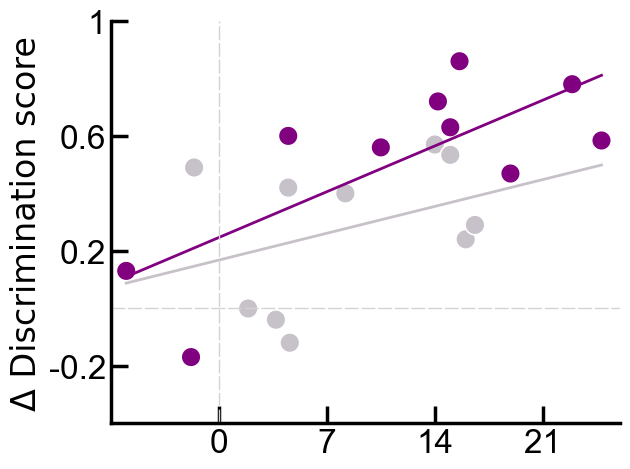

In [28]:
colors = ["purple","#c7c1c9"]

fig, ax = plt.subplots()  # create figure and axes

# plot on ax (Axes) object
# ax.plot(x, y, 'o',markersize=13,c='purple')
sns.scatterplot(data=dataframe, x='x', y='y',hue='r3r4',palette=colors,s=200)
#obtain m (slope) and b(intercept) of linear regression line
m, b = np.polyfit(x, y, 1)
m2, b2 = np.polyfit(x2,y2,1)

#add linear regression line to scatterplot 
l_reg_line = np.array([min(x.min(),x2.min()),max(x.max(),x2.max())])
ax.plot(l_reg_line, m*l_reg_line+b, color=colors[0], linewidth=2)
ax.plot(l_reg_line, m2*l_reg_line+b2, color=colors[1], linewidth=2)


#axis ticks and limits
ax.set_ylim([-0.4,1])
ax.set_yticks([-0.2,0.2,0.6,1], fontname='Arial')
ax.set_yticklabels(['-0.2','0.2','0.6','1'],fontname='Arial')

ax.set_xlim([-7,26])
ax.set_xticks([0,7,14,21], fontname='Arial')
ax.set_xticklabels(['0','7','14','21'],fontname='Arial')

sns.despine(top=True, right=True, left=False, bottom=False)
ax.spines['left'].set_linewidth(2.5)
ax.spines['bottom'].set_linewidth(2.5)
ax.set_xlabel('Δ Decoding accuracy', fontsize=24)
ax.set_xlabel('', fontsize=24)

ax.set_ylabel('Δ Discrimination score', fontsize=24)

plt.axhline(y=0,linewidth=1, color='lightgrey',ls='--', dashes=(10, 2))
plt.axvline(x=0,linewidth=1, color='lightgrey',ls='--', dashes=(10, 2))



#ax.tick_params(axis='both', which='major', )
ax.tick_params(axis='both', which='major', direction='in',length=12, labelsize=24, width=2.5)
#plt.legend(['group1', 'group2'], fontsize = 18, frameon=False, loc='upper left')
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles,['Recall 1&2', 'Recall 3&4'], fontsize = 18, frameon=False, loc='upper left')
plt.legend().remove()


plt.tight_layout()
fig.tight_layout()
fig.savefig("Fig5_DiscrCorr.jpg",dpi=500)
plt.savefig('Fig5_DiscrCorr.eps', format='eps',dpi=500)


In [4]:
x_df = list(x)
x_df.extend(x2)
y_df = list(y)
y_df.extend(y2)
flag.extend(flag_2)

dataframe = pd.DataFrame(list(zip(x_df, y_df, flag)),columns=['x','y','r3r4'])